In [2]:
# Imports
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from tensorflow.keras import Sequential, Input, layers
from tensorflow.keras import optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from keras.ops import expand_dims

from sklearn.model_selection import train_test_split


In [3]:
# Splitting train and test sets with both datasets and reshaping both X_train and X_test

train = pd.read_csv('../data/preprocessed/merged_data/processed_training_data.csv')
test  = pd.read_csv('../data/preprocessed/Testing_50_50/processed_training_data.csv')
validation  = pd.read_csv('../data/preprocessed/Validation_50_50/processed_training_data.csv')


In [7]:
validation.describe

<bound method NDFrame.describe of     label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0       X     161     165     167     170     172     174     174     177   
1       O     166     168     170     174     173     176     175     178   
2       C     192     194     194     194     194     194     195     194   
3       M     186     187     187     188     190     191     192     192   
4       Y     182     181     183     184     184     185     186     187   
..    ...     ...     ...     ...     ...     ...     ...     ...     ...   
305     Q     157     161     164     168     170     173     176     176   
306     S     159     162     163     164     164     167     170     170   
307     V     142     145     146     148     149     152     155     156   
308     Q     156     158     163     166     170     173     175     175   
309     T     158     160     166     166     167     170     172     174   

     pixel9  ...  pixel2491  pixel2492  p

In [8]:
X_train = train.loc[:, "pixel1":"pixel2500"].values.reshape(1601, 50, 50, 1) / 255.0
y_train = train.loc[:, "label"].values
X_val = validation.loc[:, "pixel1":"pixel2500"].values.reshape(310, 50, 50, 1) / 255.0
y_val = validation.loc[:, "label"].values
X_test = test.loc[:, "pixel1":"pixel2500"].values.reshape(480, 50, 50, 1) / 255.0
y_test = test.loc[:, "label"].values

In [ ]:
# Create a validation split on the test set

#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [9]:
letter_to_index = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4,
    "F": 5,
    "G": 6,
    "H": 7,
    "I": 8,
    "J": 9,
    "K": 10,
    "L": 11,
    "M": 12,
    "N": 13,
    "O": 14,
    "P": 15,
    "Q": 16,
    "R": 17,
    "S": 18,
    "T": 19,
    "U": 20,
    "V": 21,
    "W": 22,
    "X": 23,
    "Y": 24,
    "Z": 25
}

In [10]:
y_train = np.array([letter_to_index[char] for char in y_train])


In [11]:
y_val = np.array([letter_to_index[char] for char in y_val])


In [12]:
y_test = np.array([letter_to_index[char] for char in y_test])


## Model creation, fine-tuning, training

In [67]:
def initialize_model(X_train):

    model = Sequential()

    model.add(Input(shape=X_train.shape[1:]))


    ### First Convolution & MaxPooling
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPool2D(pool_size=(2, 2)))

    ### Second Convolution & MaxPooling
    model.add(layers.Conv2D(128, (3, 3), activation='relu'))
    model.add(layers.Dropout(0.2)) # please delete afterwards
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPool2D(pool_size=(2, 2)))

    ### Third Convolution & MaxPooling
    model.add(layers.Conv2D(128, (3, 3), activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPool2D(pool_size=(2, 2)))

    ### Flattening
    model.add(layers.Flatten())

    ### One Fully Connected layer - "Fully Connected" is equivalent to saying "Dense"
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.BatchNormalization())

    ### Dropout layer - rate = 0.3, fraction of units to drop
    model.add(layers.Dropout(0.3))

    ### Last layer - Classification Layer with 25 outputs corresponding to 25 digits
    model.add(layers.Dense(25, activation='softmax'))

    ### Model compilation

    adam_opt = optimizers.Adam(learning_rate=0.00001)

    model.compile(
        loss='sparse_categorical_crossentropy', # sparse if not to_categorical
        optimizer=adam_opt,
        metrics=['accuracy'])

    return model


In [68]:
# Calling model
model = initialize_model(X_train)


In [17]:
print("X_train:", X_train.shape, X_train.dtype)
print("X_val:", X_val.shape, X_val.dtype)

print("\nTraining – min/max:")
print(X_train.min(), X_train.max())

print("\nValidierung – min/max:")
print(X_val.min(), X_val.max())

print("\nTraining – Mittelwert/Standardabweichung:")
print(X_train.mean(), X_train.std())

print("\nValidierung – Mittelwert/Standardabweichung:")
print(X_val.mean(), X_val.std())

X_train: (1601, 50, 50, 1) float64
X_val: (310, 50, 50, 1) float64

Training – min/max:
0.0 1.0

Validierung – min/max:
0.0 1.0

Training – Mittelwert/Standardabweichung:
0.5349508439578204 0.22916069440425577

Validierung – Mittelwert/Standardabweichung:
0.5984132422517395 0.20686465384744213


In [18]:
print("y_train dtype:", y_train.dtype)
print("y_train shape:", y_train.shape)
print("Trainingslabels:", np.unique(y_train))

print("\ny_val dtype:", y_val.dtype)
print("y_val shape:", y_val.shape)
print("Validierungslabels:", np.unique(y_val))

y_train dtype: int64
y_train shape: (1601,)
Trainingslabels: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]

y_val dtype: int64
y_val shape: (310,)
Validierungslabels: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


In [69]:
# Model Summary
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_31 (Conv2D)              │ (None, 50, 50, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 50, 50, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 23, 23, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 23, 23, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 9, 9, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 9, 9, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,065 (1.22 MB)

 Trainable params: 318,361 (1.21 MB)

 Non-trainable params: 704 (2.75 KB)

In [70]:
# Call EarlyStopping and train model
lr = ReduceLROnPlateau(monitor = 'val_loss', factor=0.1, patience=5, verbose=1, min_lr=0)

es = EarlyStopping(patience=5, monitor='val_loss', verbose=1, restore_best_weights=True)

history = model.fit(X_train, y_train,
         batch_size=16,
         epochs=200,
         callbacks=[lr],
         validation_data=(X_val, y_val),
         verbose=1)

Epoch 1/200
101/101 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - accuracy: 0.0506 - loss: 3.9026 - val_accuracy: 0.0419 - val_loss: 3.5336 - learning_rate: 1.0000e-05
Epoch 2/200
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.0962 - loss: 3.4269 - val_accuracy: 0.0419 - val_loss: 4.1815 - learning_rate: 1.0000e-05
Epoch 3/200
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.1437 - loss: 3.1210 - val_accuracy: 0.0419 - val_loss: 4.6253 - learning_rate: 1.0000e-05
Epoch 4/200
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.1999 - loss: 2.8636 - val_accuracy: 0.0323 - val_loss: 4.4213 - learning_rate: 1.0000e-05
Epoch 5/200
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.2755 - loss: 2.6197 - val_accuracy: 0.0581 - val_loss: 3.7130 - learning_rate: 1.0000e-05
Epoch 6/200
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.3161 - loss: 2.4370 - val_accuracy: 0.0968 - val_loss: 3.2431 - learning_rate: 1.0000e-05
Epoch 7/200
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/st

In [71]:
model.evaluate(X_test, y_test, verbose=1)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3792 - loss: 2.1160


[2.1160364151000977, 0.3791666626930237]

In [72]:
csv_history = history.history

In [65]:
model.save('model_50_merged_data_0.46.keras')

Things to add:
- Embedding layer

Things to ask:
- Do we need masking here ? aka embedding layer

In [9]:
# Import model as pkl file on models
import joblib

with open("mnist_baseline_model", "wb") as file:
    joblib.dump(model, file)

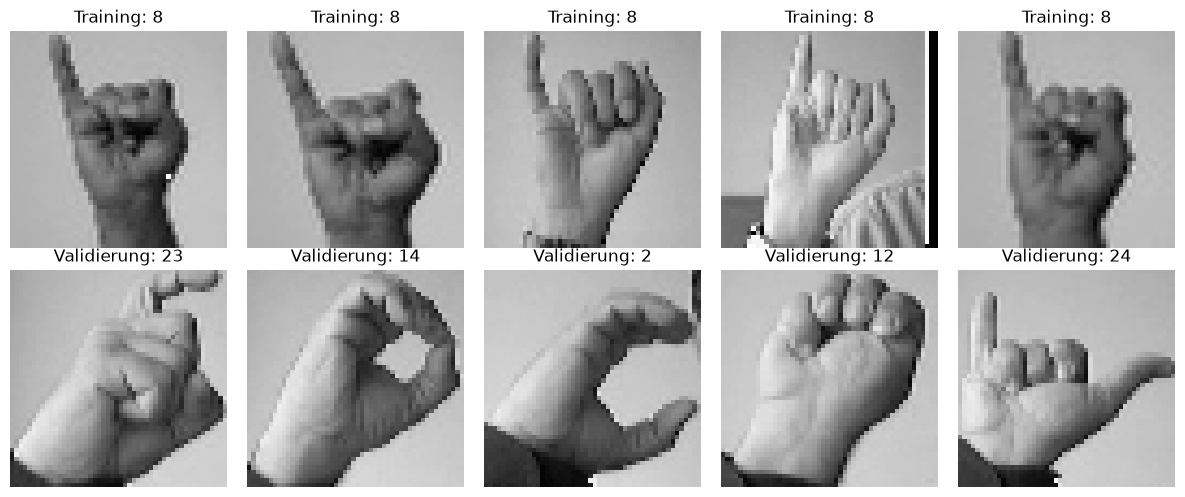

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    axes[0, i].imshow(X_train[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Training: {y_train[i]}")
    axes[0, i].axis("off")

    axes[1, i].imshow(X_val[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title(f"Validierung: {y_val[i]}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()